In [1]:
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm as tq

In [2]:
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [3]:
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Rescaling
from tensorflow.keras.layers import RandomRotation, RandomTranslation, RandomZoom, RandomFlip
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

In [4]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [5]:
# Setingan Manual Model
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 123
RANDOM_STATE = 42

In [6]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="lTX5TC3cer6byJhlu3gd")
project = rf.workspace("web-developer-nnzvr").project("dataset-daun-cabai-kuwq2")
version = project.version(1)
dataset = version.download("folder")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 80.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.0 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dataset-daun-cabai-1 in folder:: 100%|██████████| 2202/2202 [00:00<00:00, 8924.61it/s]


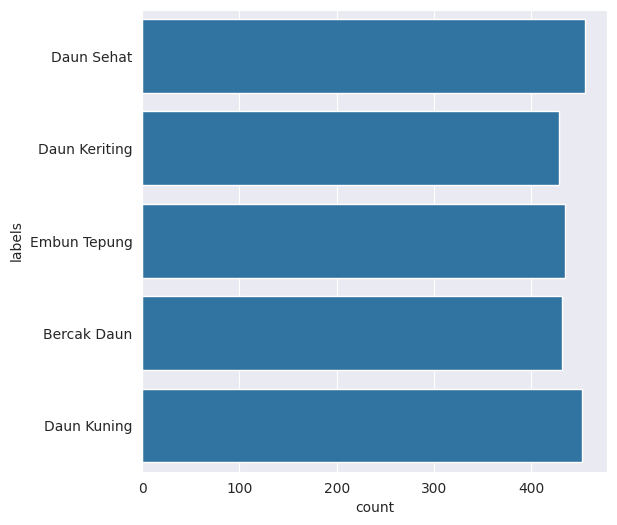

In [11]:
lung_path = "dataset-daun-cabai-1"
file_name = []
labels = []
full_path = []
set_data = []

for f_path in os.listdir(lung_path):
  for path, subdirs, files in os.walk(os.path.join(lung_path, f_path)):
    for name in files:
      full_path.append(os.path.join(path, name))
      labels.append(path.split("/")[-1])
      file_name.append(name)
      set_data.append(path.split("/")[-2])

distribution_image = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels, "set":set_data})

Label = distribution_image['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

In [12]:
for distribusion in distribution_image['labels'].unique():
  print(f"Total {distribusion} : {distribution_image[distribution_image['labels'] == distribusion].count()['labels']}")

print("===================================================")
print(f"Total Dataset Image Keseluruhan : {Label.count()}")

Total Daun Sehat : 455
Total Daun Keriting : 428
Total Embun Tepung : 434
Total Bercak Daun : 431
Total Daun Kuning : 452
Total Dataset Image Keseluruhan : 2200


In [15]:
df = distribution_image.copy()
df.head()

,path,file_name,labels,set
0,dataset-daun-cabai-1/train/Daun Sehat/Healthy-...,Healthy-Leaf00165_JPG_jpg.rf.af3f853f9e06986e1...,Daun Sehat,train
1,dataset-daun-cabai-1/train/Daun Sehat/Healthy-...,Healthy-Leaf00169_JPG_jpg.rf.f1e156bbc19c95b9e...,Daun Sehat,train
2,dataset-daun-cabai-1/train/Daun Sehat/Healthy-...,Healthy-Leaf00278_JPG.rf.7eb727f5b0bd50793ca42...,Daun Sehat,train
3,dataset-daun-cabai-1/train/Daun Sehat/Healthy-...,Healthy-Leaf00005_JPG_jpg.rf.d42d0c7c8dd65ea24...,Daun Sehat,train
4,dataset-daun-cabai-1/train/Daun Sehat/Healthy-...,Healthy-Leaf00188_JPG_jpg.rf.d3d9e92df0e184e8e...,Daun Sehat,train


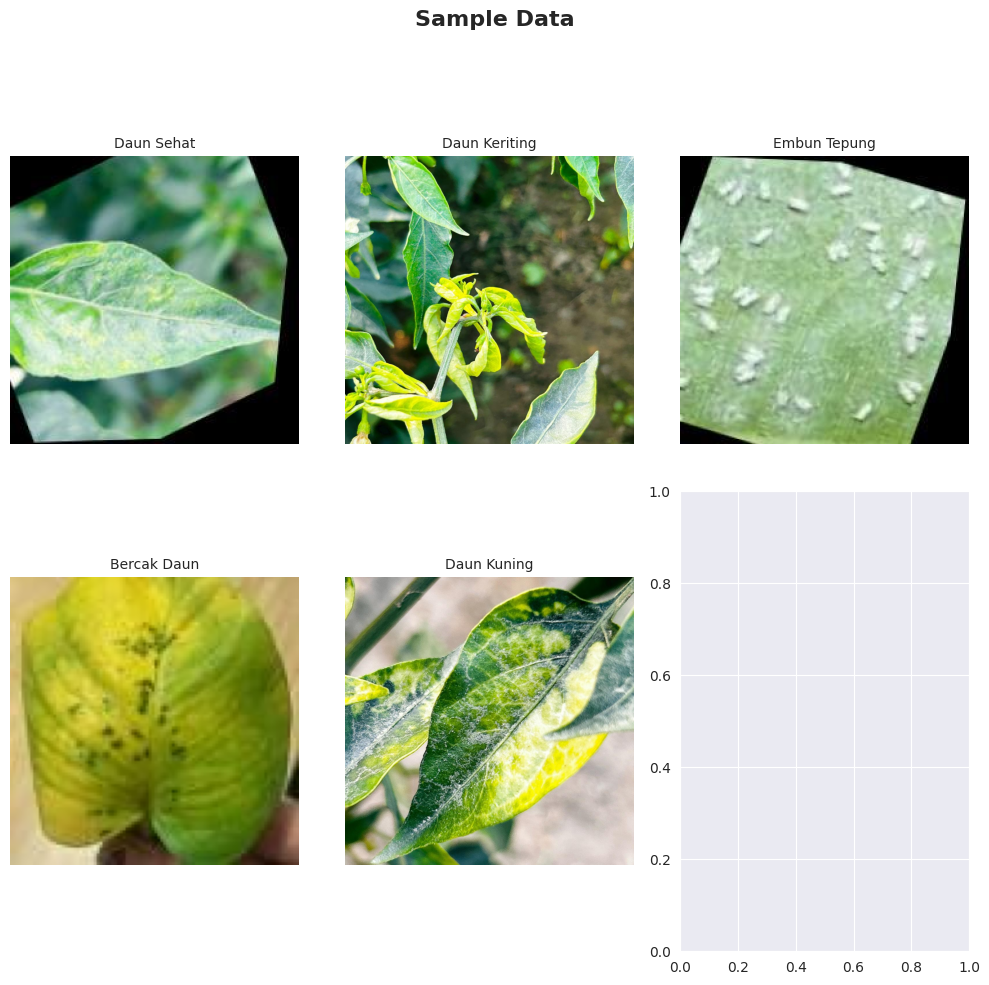

In [18]:
unique_labels = df['labels'].unique()

fig, axes = plt.subplots(2, 3, figsize=(10, 10))
fig.suptitle("Sample Data", fontsize=16, fontweight='bold')

axes = axes.flatten()

for i, uniq in enumerate(unique_labels):
    sample_path = df[df['labels'] == uniq]['path'].values[0]

    img = Image.open(sample_path)

    axes[i].imshow(img)
    axes[i].set_title(uniq, fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

In [19]:
df.groupby(["set", "labels"]).size()

set    labels       
test   Bercak Daun       46
       Daun Keriting     38
       Daun Kuning       48
       Daun Sehat        35
       Embun Tepung      53
train  Bercak Daun      328
       Daun Keriting    350
       Daun Kuning      372
       Daun Sehat       372
       Embun Tepung     338
valid  Bercak Daun       57
       Daun Keriting     40
       Daun Kuning       32
       Daun Sehat        48
       Embun Tepung      43
dtype: int64

In [22]:
TRAIN_DIR = f"{lung_path}/train/"
TEST_DIR = f"{lung_path}/test/"
VALID_DIR = f"{lung_path}/valid/"
arr_train = []
arr_test = []
arr_valid = []

for key, data in enumerate(os.listdir(TRAIN_DIR)):
  dict_train = {"train_name" : f"train_{data}",
                "train_path" : os.path.join(f"{TRAIN_DIR}{data}")}
  arr_train.append(dict_train)
for key, data in enumerate(os.listdir(TEST_DIR)):
  dict_test = {"test_name" : f"test_{data}",
                "test_path" : os.path.join(f"{TEST_DIR}{data}")}
  arr_test.append(dict_test)
for key, data in enumerate(os.listdir(VALID_DIR)):
  dict_valid = {"valid_name" : f"valid_{data}",
                "valid_path" : os.path.join(f"{VALID_DIR}{data}")}
  arr_valid.append(dict_valid)

for ar_tr in arr_train:
  print(f"Total number of {ar_tr["train_name"].replace("_", " ")} : {len(os.listdir(ar_tr["train_path"]))}")

print("===================================================")

for ar_ts in arr_test:
  print(f"Total number of {ar_ts["test_name"].replace("_", " ")} : {len(os.listdir(ar_ts["test_path"]))}")

print("===================================================")

for ar_vl in arr_valid:
  print(f"Total number of {ar_vl["valid_name"].replace("_", " ")} : {len(os.listdir(ar_vl["valid_path"]))}")

Total number of train Daun Sehat : 372
Total number of train Daun Keriting : 350
Total number of train Embun Tepung : 338
Total number of train Bercak Daun : 328
Total number of train Daun Kuning : 372
Total number of test Daun Sehat : 35
Total number of test Daun Keriting : 38
Total number of test Embun Tepung : 53
Total number of test Bercak Daun : 46
Total number of test Daun Kuning : 48
Total number of valid Daun Sehat : 48
Total number of valid Daun Keriting : 40
Total number of valid Embun Tepung : 43
Total number of valid Bercak Daun : 57
Total number of valid Daun Kuning : 32


In [24]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR, seed=SEED, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False
)
class_names = test_dataset.class_names
NUM_CLASSES = len(train_dataset.class_names)
print(f"Jumlah kelas terdeteksi: {NUM_CLASSES}")

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Found 1760 files belonging to 5 classes.
Found 220 files belonging to 5 classes.
Found 220 files belonging to 5 classes.
Jumlah kelas terdeteksi: 5


In [25]:
data_augmentation = Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomTranslation(height_factor=0.2, width_factor=0.2),
    RandomZoom(0.2),
], name="augmentation_layer")

# LAYER BARU KHUSUS MOBILENETV2 (Rumus: (x / 127.5) - 1 )
# Ini mengubah rentang 0-255 menjadi -1 sampai 1
mobilenet_preprocess = Rescaling(scale=1./127.5, offset=-1, name="mobilenet_rescale")

# Muat Base Model MobileNetV2
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# Rangkai Model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = mobilenet_preprocess(x)         # <--- Masukkan layer rescale di sini!
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs, outputs)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [26]:
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(filepath='model_tomat_mobilenetv2.keras', monitor='val_accuracy', save_best_only=True)
]

In [27]:
print("\n--- MULAI TAHAP 1: FEATURE EXTRACTION ---")
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])

history_1 = model.fit(train_dataset, validation_data=val_dataset, epochs=15, callbacks=callbacks_list)


--- MULAI TAHAP 1: FEATURE EXTRACTION ---
Epoch 1/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 18s 111ms/step - accuracy: 0.5523 - loss: 1.1355 - val_accuracy: 0.8045 - val_loss: 0.5307 - learning_rate: 0.0010
Epoch 2/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - accuracy: 0.8273 - loss: 0.5209 - val_accuracy: 0.8409 - val_loss: 0.3946 - learning_rate: 0.0010
Epoch 3/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.8585 - loss: 0.4007 - val_accuracy: 0.8682 - val_loss: 0.3320 - learning_rate: 0.0010
Epoch 4/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.8932 - loss: 0.3425 - val_accuracy: 0.8818 - val_loss: 0.2930 - learning_rate: 0.0010
Epoch 5/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - accuracy: 0.8807 - loss: 0.3332 - val_accuracy: 0.9182 - val_loss: 0.2313 - learning_rate: 0.0010
Epoch 6/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.8966 - loss: 0.2978 - val_accuracy: 0.9182 - val_loss: 0.2185 - learning_rate: 0.0010
Epoch 7/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/ste

In [28]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9273 - loss: 0.1991
--------------------------------------------------
TEST ACCURACY: 0.9273 (92.73%)
TEST LOSS:     0.1991
--------------------------------------------------


In [29]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 212ms/step

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

  Bercak Daun       0.91      0.93      0.92        46
Daun Keriting       1.00      0.84      0.91        38
  Daun Kuning       0.87      0.98      0.92        48
   Daun Sehat       0.92      1.00      0.96        35
 Embun Tepung       0.96      0.89      0.92        53

     accuracy                           0.93       220
    macro avg       0.93      0.93      0.93       220
 weighted avg       0.93      0.93      0.93       220



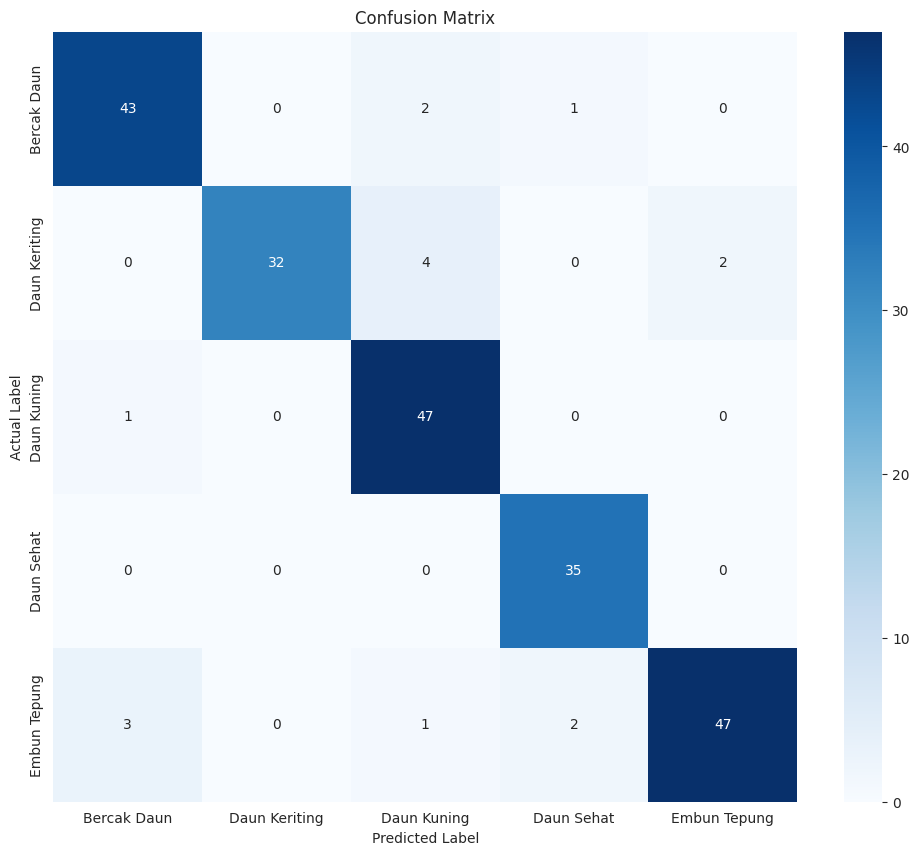

In [30]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

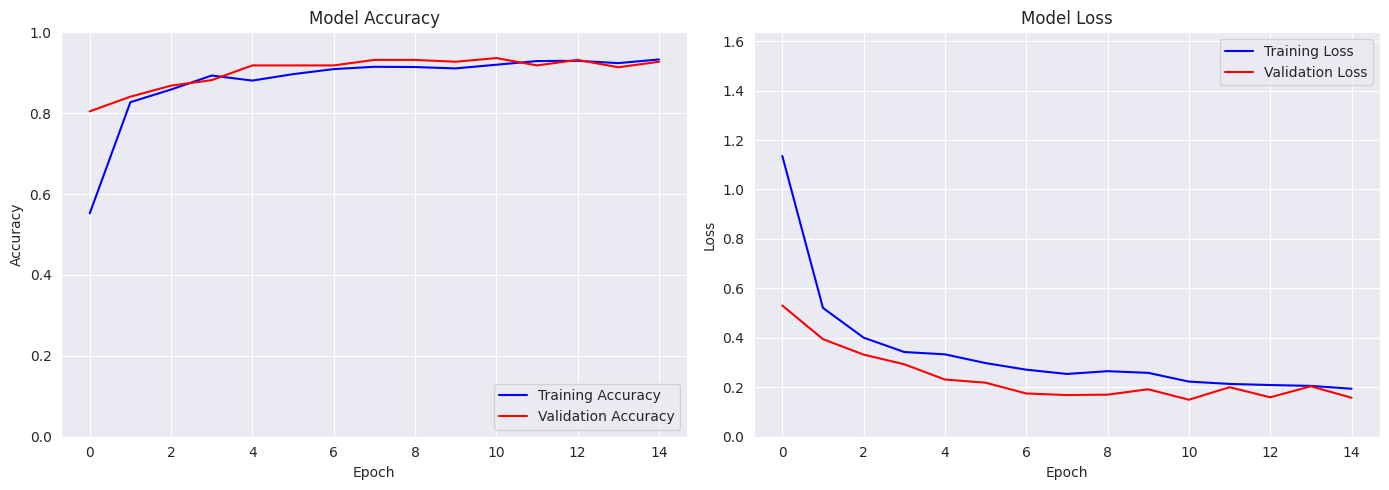

In [31]:
if 'history_1' in locals():
    acc = history_1.history['accuracy']
    val_acc = history_1.history['val_accuracy']
    loss = history_1.history['loss']
    val_loss = history_1.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [32]:
shutil.copy("/content/model_tomat_mobilenetv2.keras", "/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Model/MobileNetV2_pre-trained.keras")

'/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Model/MobileNetV2_pre-trained.keras'

In [34]:
def predict_image(img_path, model, class_names):
    # 1. Muat gambar dan pastikan ukurannya sesuai dengan input model
    img = image.load_img(img_path, target_size=(224, 224))

    # 2. Ubah gambar menjadi array
    img_array = image.img_to_array(img)

    # 3. Tambahkan dimensi batch (dari (224, 224, 3) menjadi (1, 224, 224, 3))
    img_array = np.expand_dims(img_array, axis=0)

    # CATATAN: Rescale (img_array /= 255.0) sengaja ditiadakan untuk EfficientNet

    # 4. Lakukan prediksi
    predictions = model.predict(img_array)

    # 5. Ekstrak hasil
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0])

    print(f'Predicted: {class_names[predicted_class]} (Confidence: {confidence:.2%})')

    # Opsional: Kembalikan nilai jika ingin digunakan di variabel lain
    return class_names[predicted_class], confidence

predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/63847b2635b1f.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/chilli-cercospora-leaf-spot-pepper-1560239911.jpg', model, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Predicted: Bercak Daun (Confidence: 98.30%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
Predicted: Daun Sehat (Confidence: 61.91%)


('Daun Sehat', np.float32(0.6191135))

In [35]:
print("\n--- MULAI TAHAP 2: FINE TUNING ---")
base_model.trainable = True

# Biarkan Batch Normalization membeku
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # LR SANGAT KECIL
              loss='categorical_crossentropy', metrics=['accuracy'])

history_2 = model.fit(train_dataset, validation_data=val_dataset, epochs=20, callbacks=callbacks_list)


--- MULAI TAHAP 2: FINE TUNING ---
Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 21s 183ms/step - accuracy: 0.9347 - loss: 0.1893 - val_accuracy: 0.9409 - val_loss: 0.1553 - learning_rate: 1.0000e-05
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 138ms/step - accuracy: 0.9455 - loss: 0.1328 - val_accuracy: 0.9545 - val_loss: 0.1163 - learning_rate: 1.0000e-05
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 138ms/step - accuracy: 0.9648 - loss: 0.0971 - val_accuracy: 0.9727 - val_loss: 0.0757 - learning_rate: 1.0000e-05
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 127ms/step - accuracy: 0.9619 - loss: 0.1125 - val_accuracy: 0.9682 - val_loss: 0.1048 - learning_rate: 1.0000e-05
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 139ms/step - accuracy: 0.9682 - loss: 0.0896 - val_accuracy: 0.9818 - val_loss: 0.0645 - learning_rate: 1.0000e-05
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - accuracy: 0.9682 - loss: 0.0762 - val_accuracy: 0.9591 - val_loss: 0.0847 - learning_rate: 1.0000e-05
Epoch 7/20
55/55 ━━━━━━━━━━

In [37]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9955 - loss: 0.0145
--------------------------------------------------
TEST ACCURACY: 0.9955 (99.55%)
TEST LOSS:     0.0145
--------------------------------------------------


In [38]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 224ms/step

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

  Bercak Daun       0.98      1.00      0.99        46
Daun Keriting       1.00      1.00      1.00        38
  Daun Kuning       1.00      1.00      1.00        48
   Daun Sehat       1.00      1.00      1.00        35
 Embun Tepung       1.00      0.98      0.99        53

     accuracy                           1.00       220
    macro avg       1.00      1.00      1.00       220
 weighted avg       1.00      1.00      1.00       220



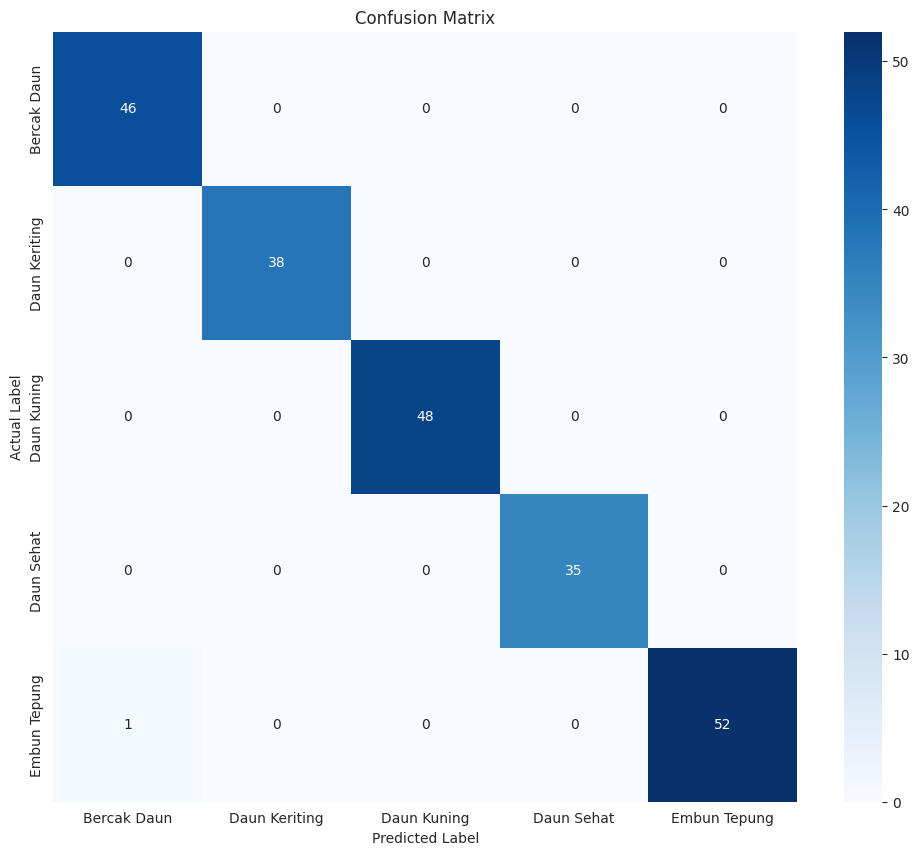

In [39]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

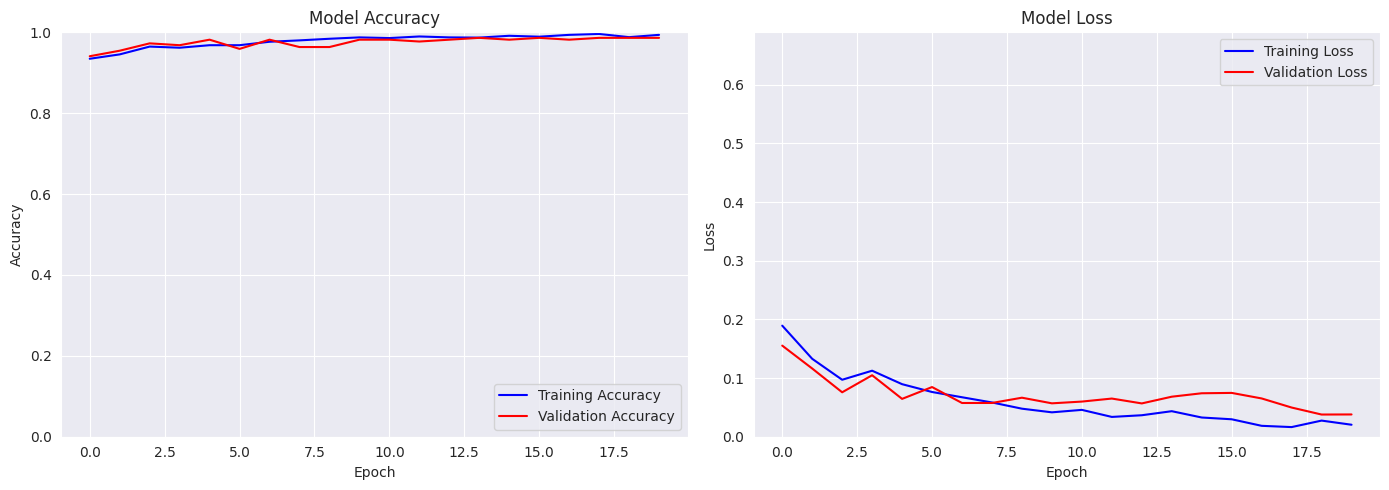

In [40]:
if 'history_2' in locals():
    acc = history_2.history['accuracy']
    val_acc = history_2.history['val_accuracy']
    loss = history_2.history['loss']
    val_loss = history_2.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [44]:
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/63847b2635b1f.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/chilli-cercospora-leaf-spot-pepper-1560239911.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/keriting1.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/keriting2.webp', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/embun1.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/embun2.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/kuning1.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/kuning2.jpg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Sample/kuning3.jpg', model, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
Predicted: Bercak Daun (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
Predicted: Bercak Daun (Confidence: 99.97%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
Predicted: Daun Keriting (Confidence: 98.86%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
Predicted: Daun Keriting (Confidence: 95.48%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
Predicted: Embun Tepung (Confidence: 87.38%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
Predicted: Embun Tepung (Confidence: 86.07%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Predicted: Daun Keriting (Confidence: 100.00%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Predicted: Bercak Daun (Confidence: 98.84%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Predicted: Daun Keriting (Confidence: 100.00%)


('Daun Keriting', np.float32(0.9999894))

In [45]:
shutil.copy("/content/model_tomat_mobilenetv2.keras", "/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Model/MobileNetV2_fine-tuning.keras")

'/content/drive/MyDrive/DEEP LEARNING/Chili Disease/Model/MobileNetV2_fine-tuning.keras'

In [46]:
class_names

['Bercak Daun', 'Daun Keriting', 'Daun Kuning', 'Daun Sehat', 'Embun Tepung']